# 16 · Direct moisture inversion, SMI methods, rainfall and geographic snapshots

This notebook displays the six-point results without running new inversions. **Rainfall is an overlay, not an inversion input.** Maps show only measured point locations; no full-raster estimates are implied.

| Plot family | Retrieval | Output |
|---|---|---|
| Direct: Hallikainen / Ulaby–Dobson / Wang–Schmugge | Bounded multistart fitting of wrapped triangle closures through a dielectric/scattering model | Conditional m³/m³; assumed initial moisture 0.10 |
| Event SMI | Exponential-event fit to BW1-minus-full closure history | Normalized relative index |
| Normalized gradient | Gradient of smoothed closure history | Normalized relative index |
| Robust Event SMI | Event fit with robust residual loss | Normalized relative index |

The direct experiment has 6 converged fits, 11 iteration-limited fits and 1 rejection; convergence is not validation. The models produce different solutions from different starting guesses. See [source audit](../../MiaplPy/docs/dielectric_model_review_20261015.md).


In [1]:
from pathlib import Path
import json
from IPython.display import display, Image, Markdown
candidates = [Path.cwd(), *Path.cwd().parents]
project = next(p for p in candidates if (p/'MiaplPy').is_dir() and (p/'NavaSAR').is_dir())
figures = project/'MiaplPy/results/moisture_method_figures_20261015'
manifest = json.loads((figures/'manifest.json').read_text())
print('Snapshot dates:', manifest['snapshot_dates'])
print('Figures:', figures)


Snapshot dates: ['2017-01-05', '2017-12-07', '2018-12-02', '2019-11-15']
Figures: /raid2-gpu2/maref/Thesis_final_project/MiaplPy/results/moisture_method_figures_20261015


## Direct inversion: three dielectric models, without external overlays

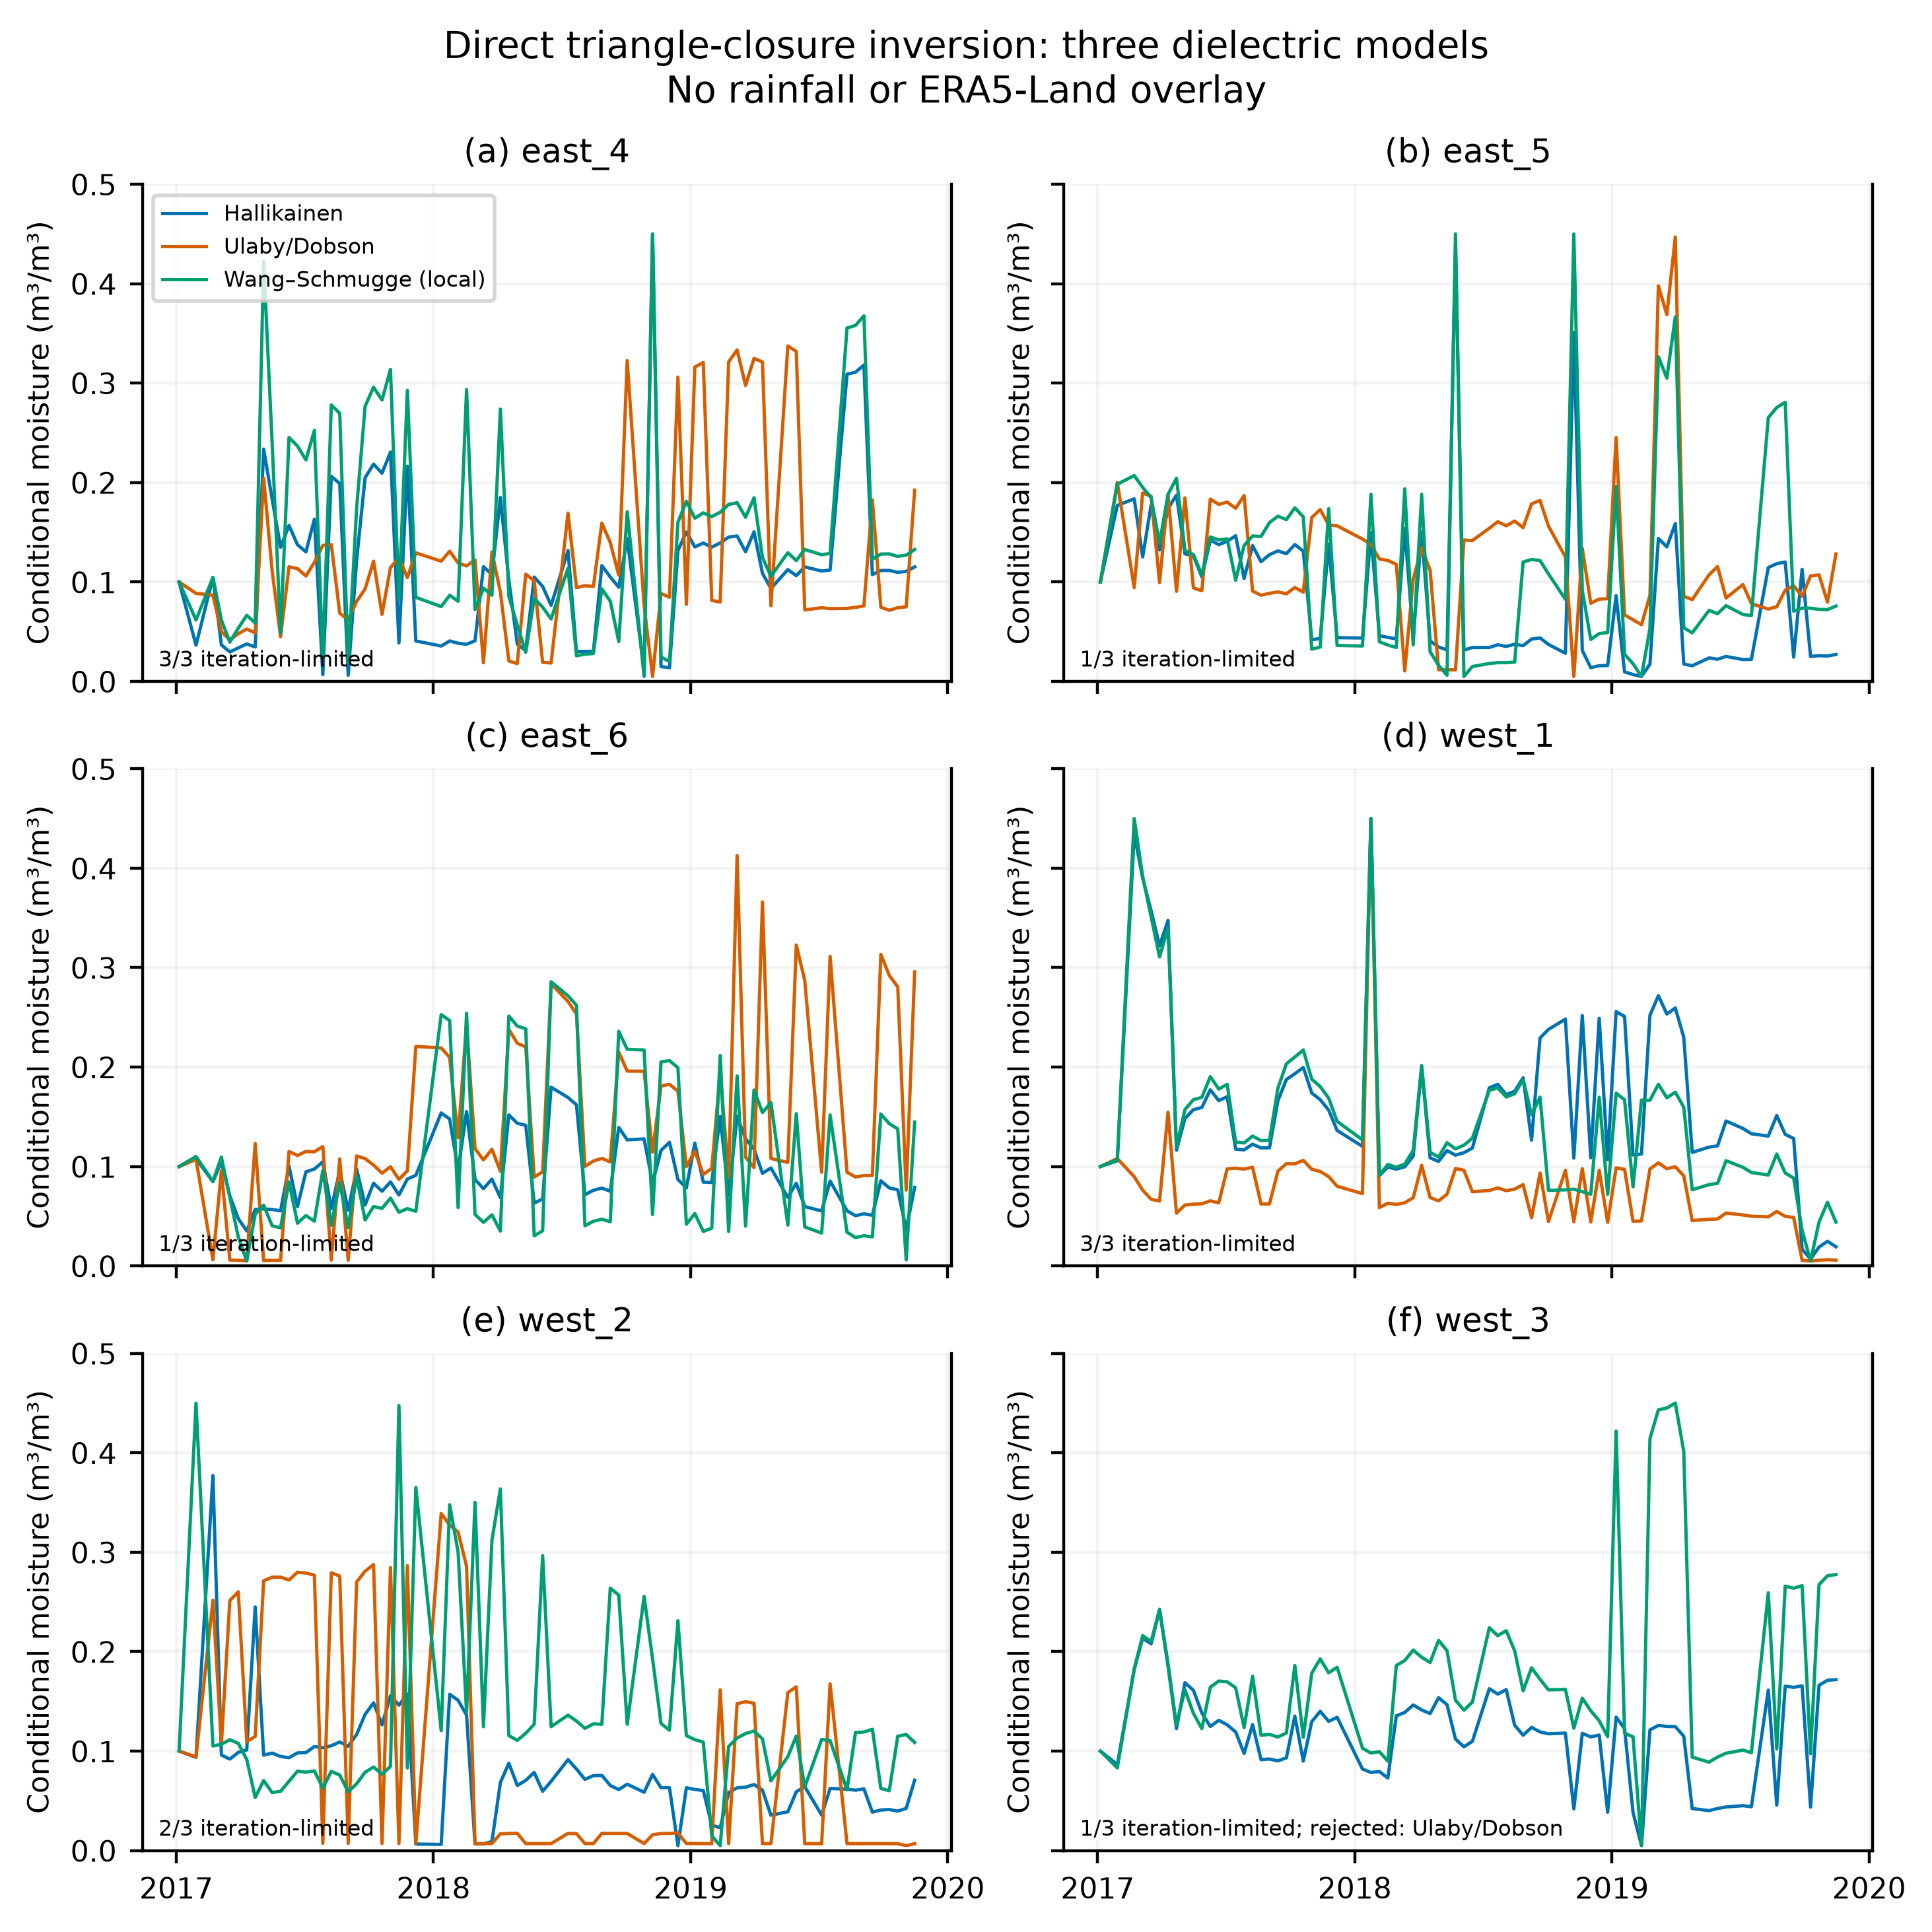

## The same direct inversions with ERA5 rainfall

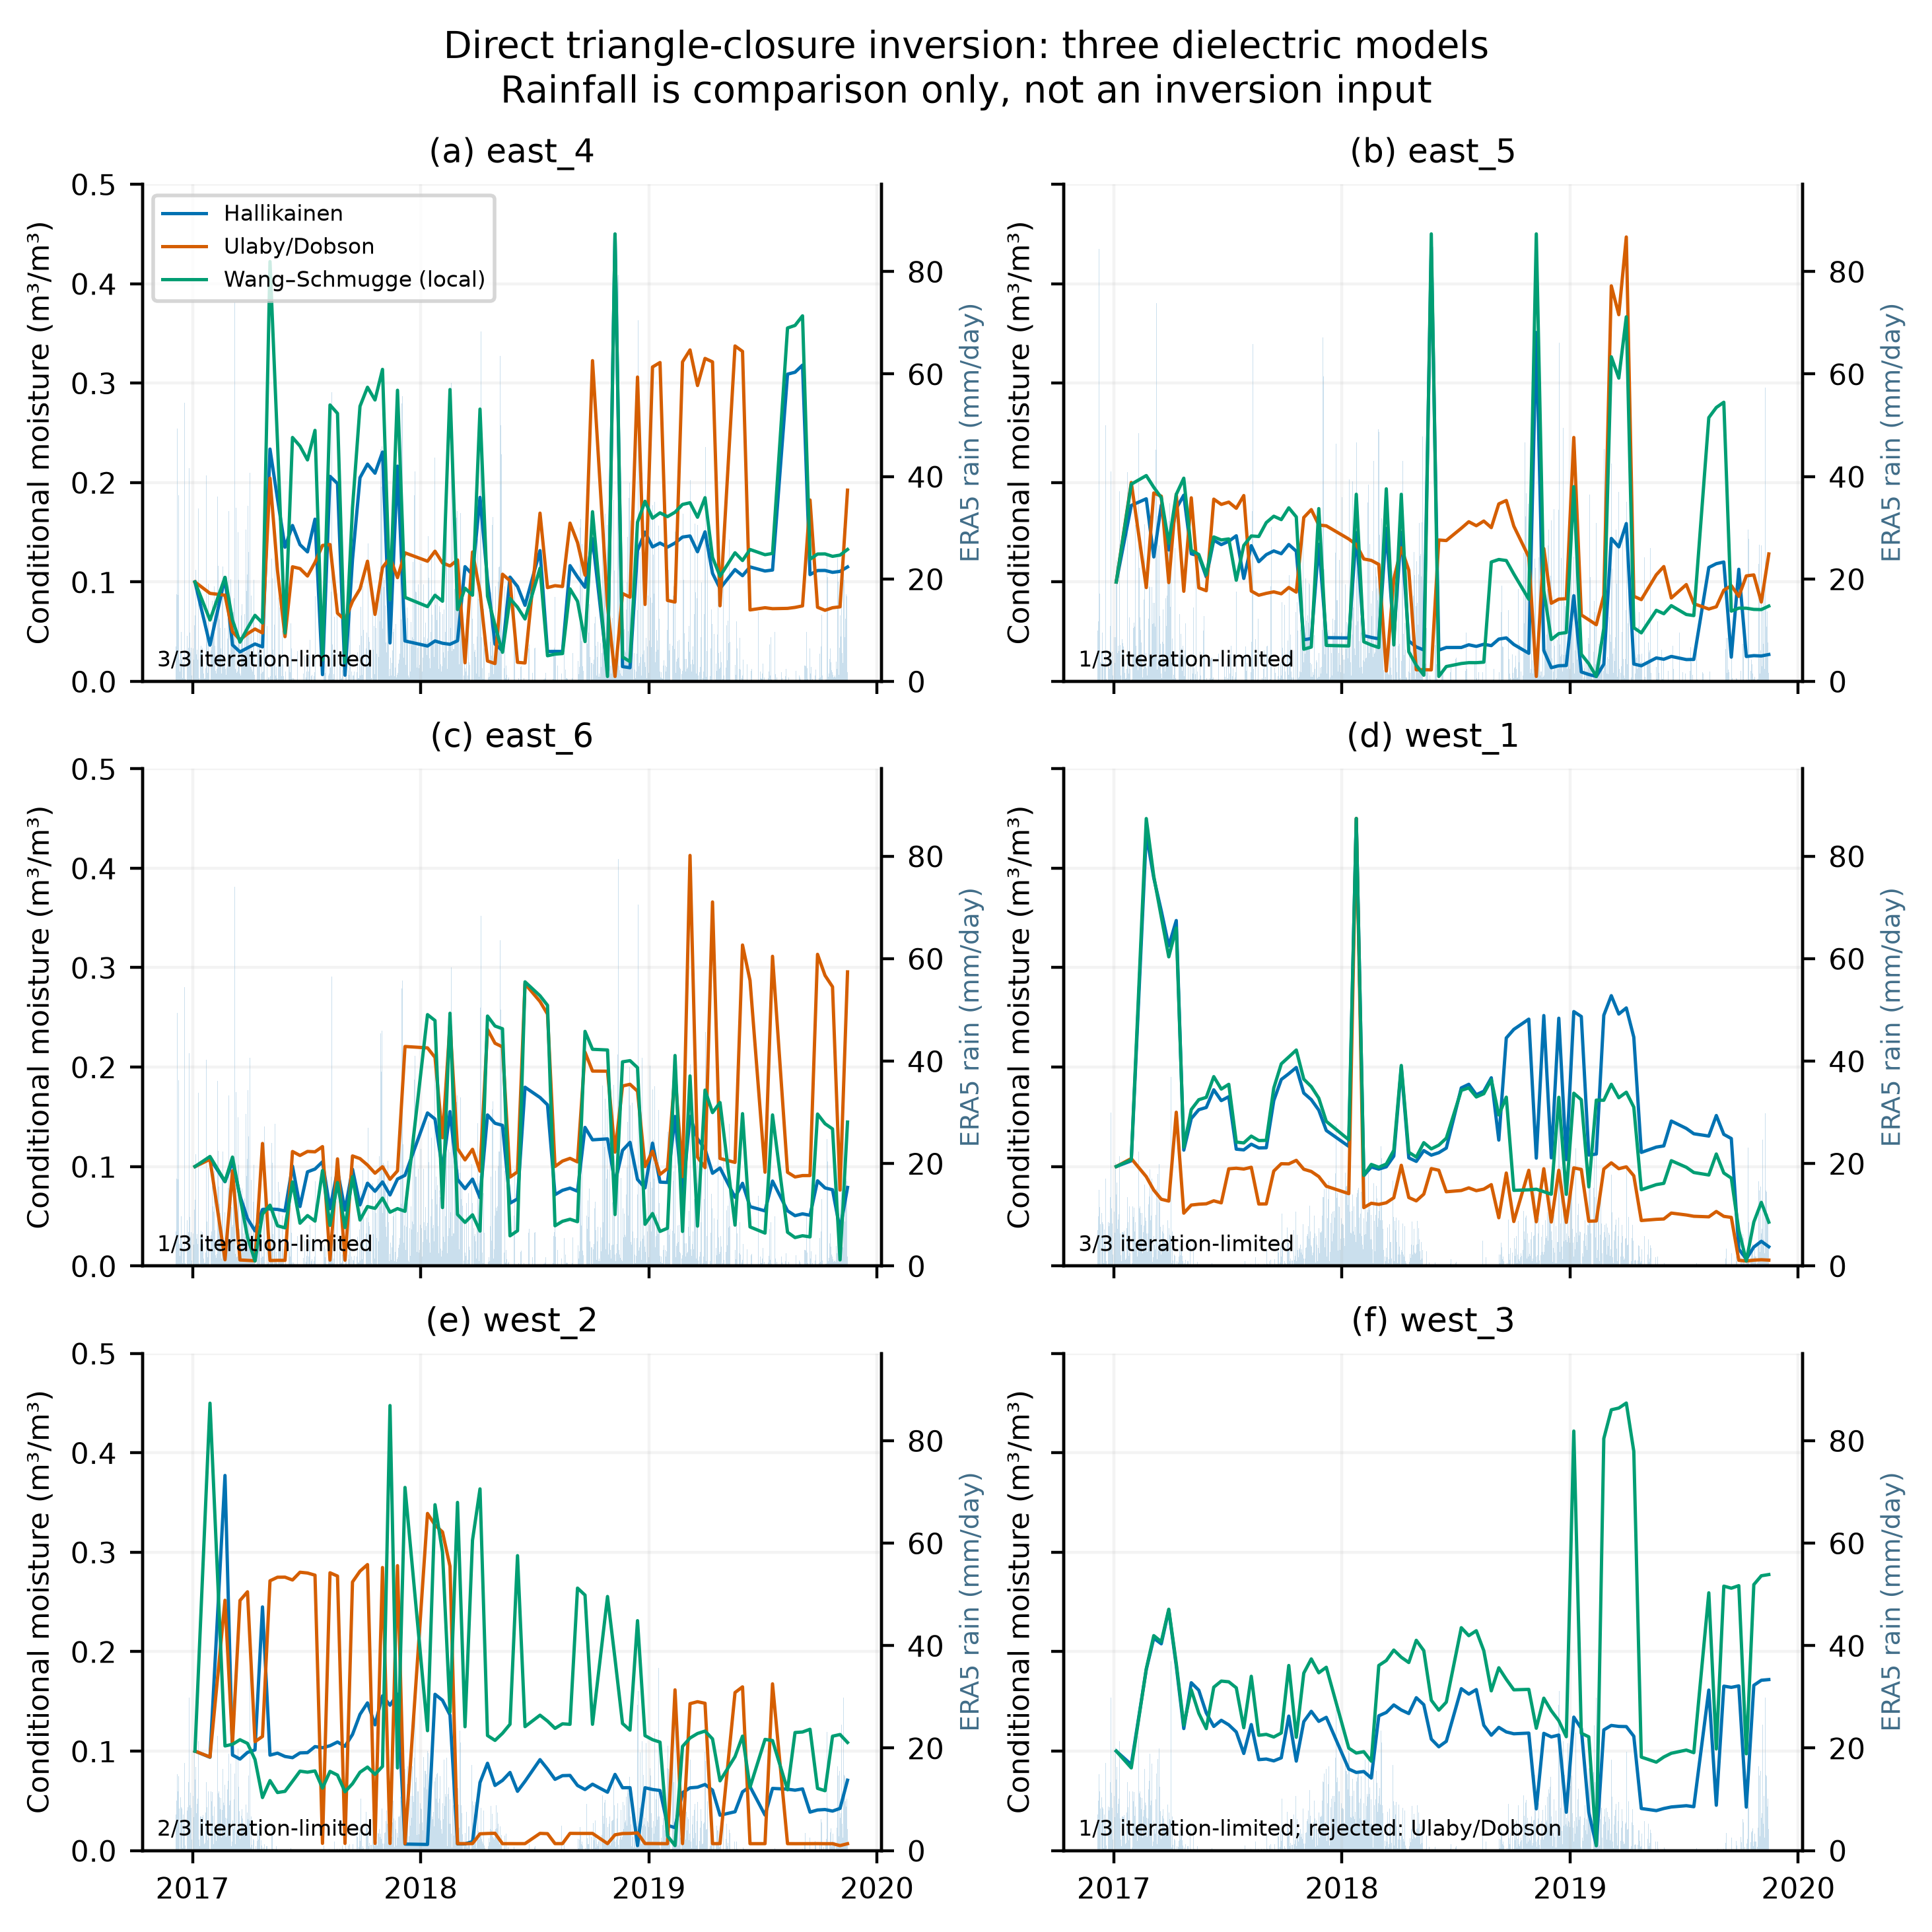

In [2]:
display(Markdown('## Direct inversion: three dielectric models, without external overlays'))
display(Image(filename=str(figures/'direct_only.png')))
display(Markdown('## The same direct inversions with ERA5 rainfall'))
display(Image(filename=str(figures/'direct_with_rainfall.png')))


## Separate retrieval family: Event, gradient and robust-event indices

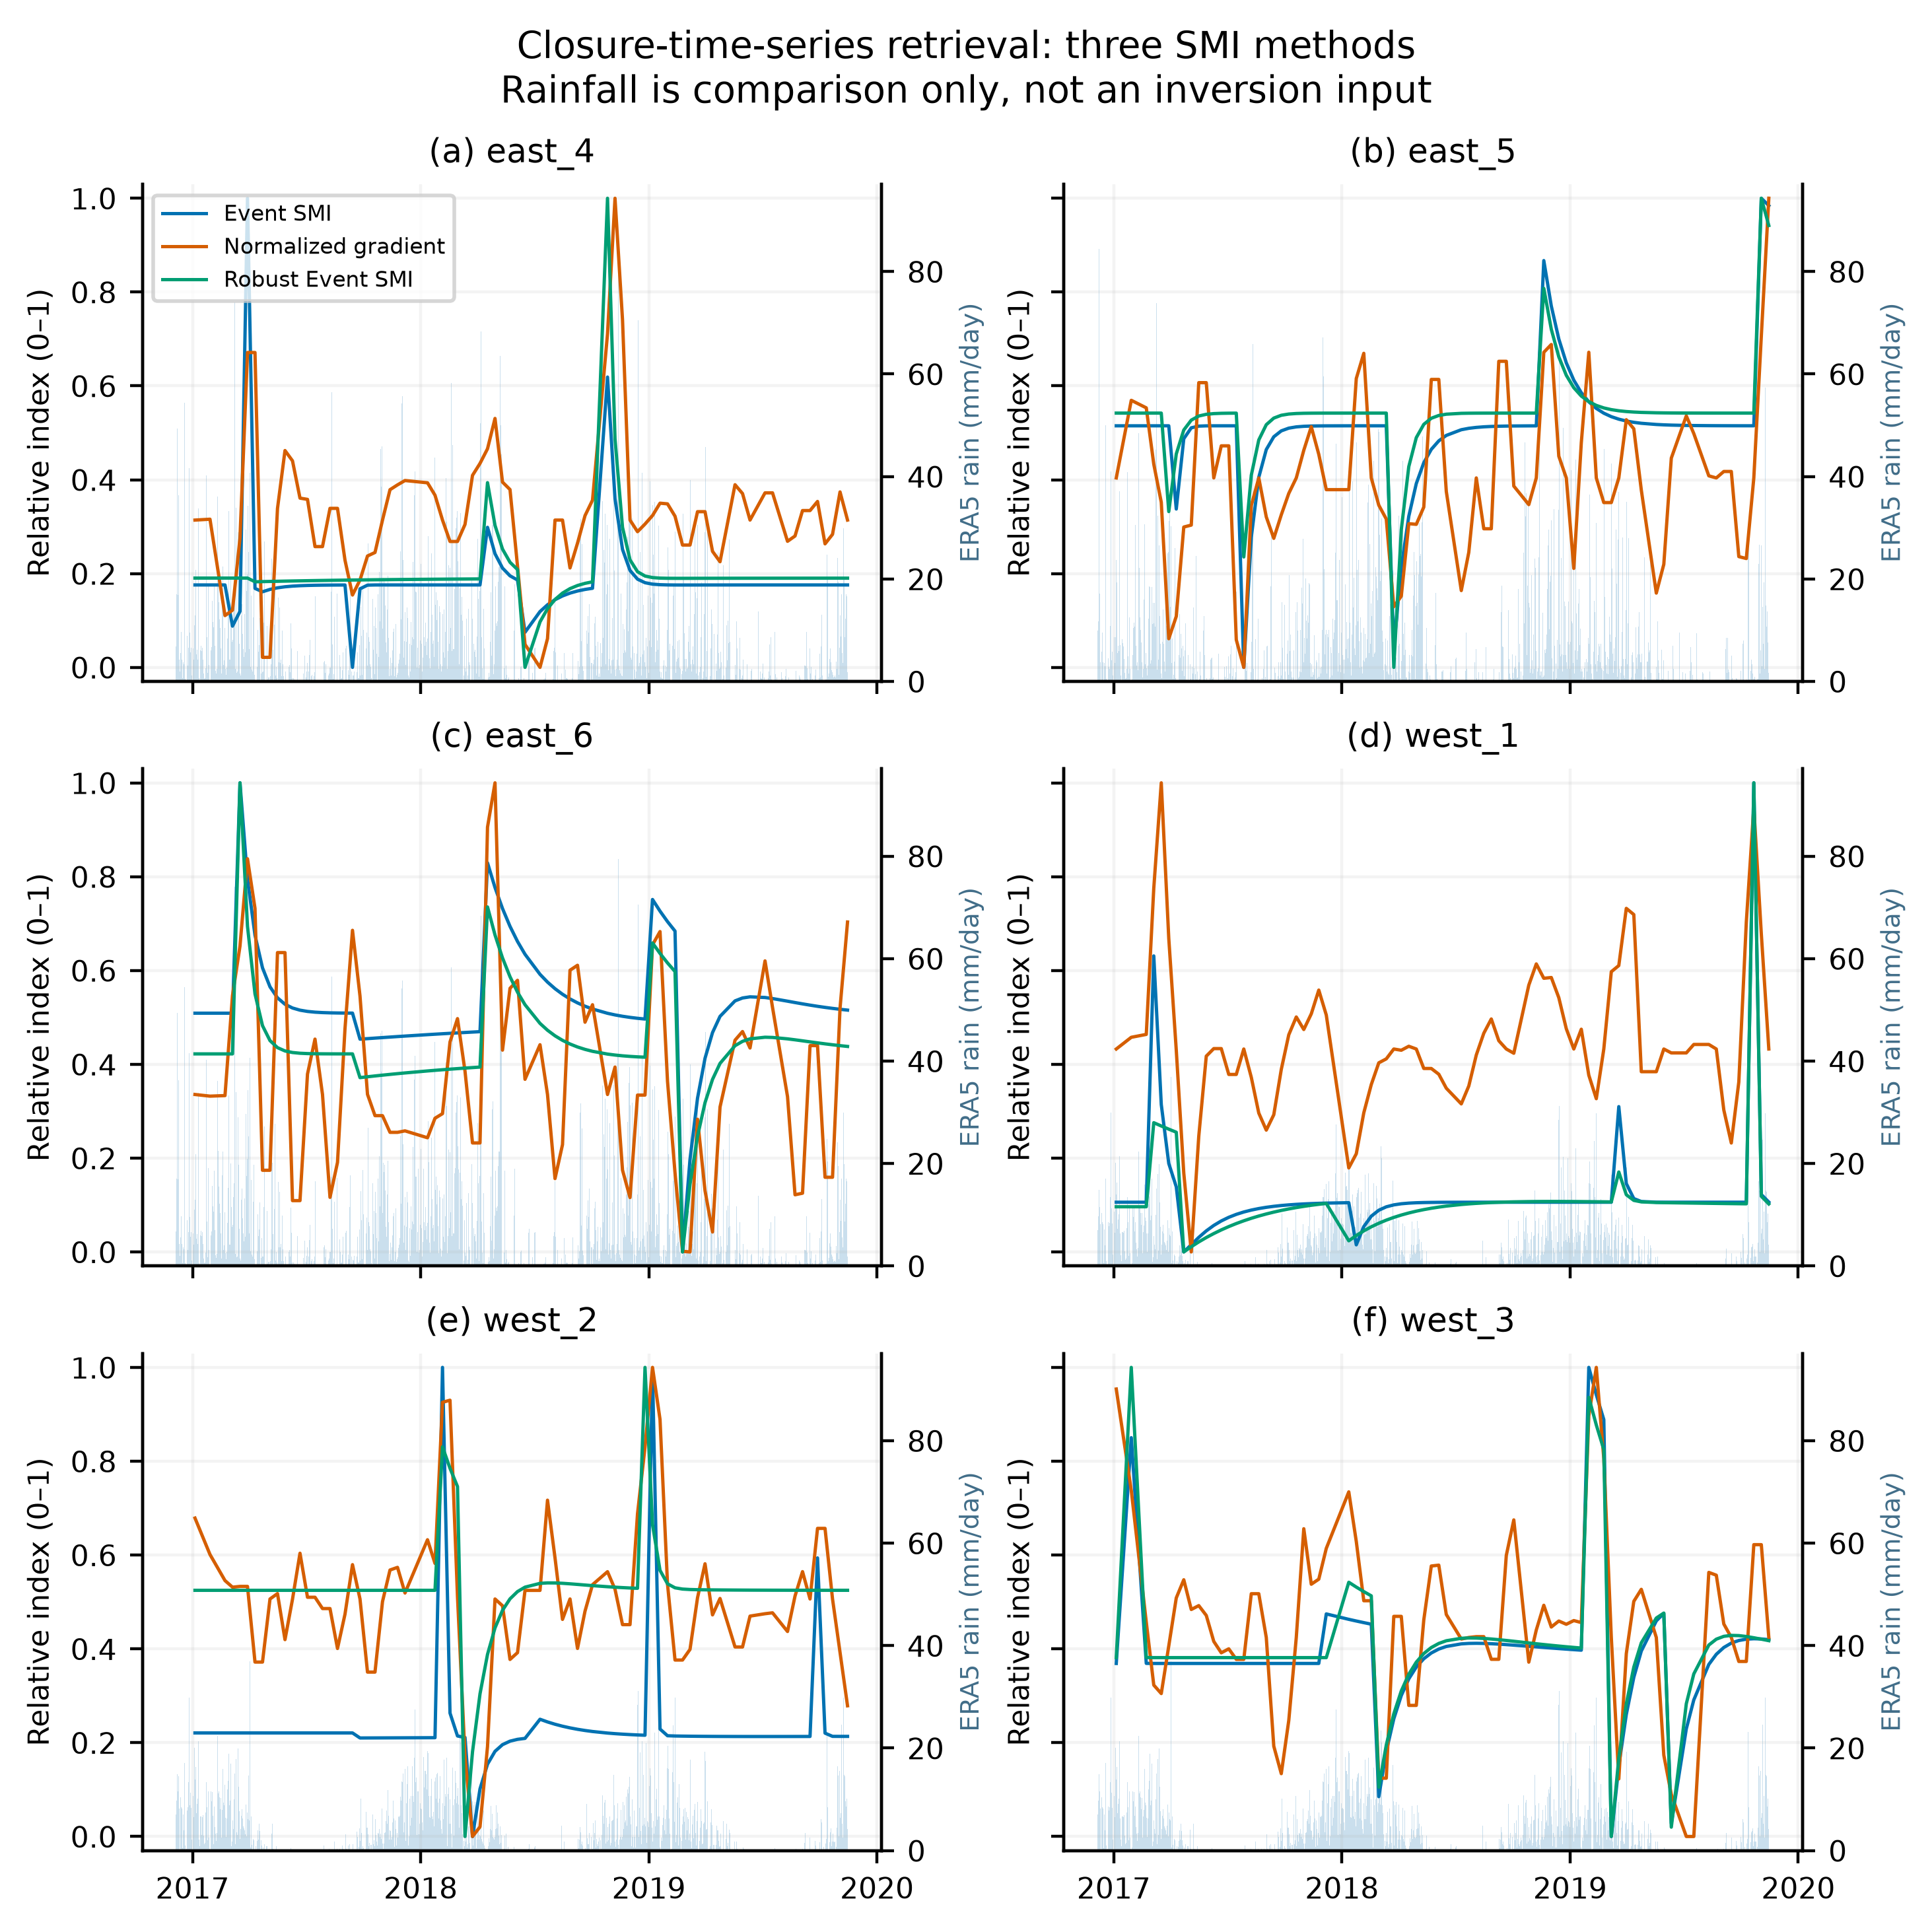

In [3]:
display(Markdown('## Separate retrieval family: Event, gradient and robust-event indices'))
display(Image(filename=str(figures/'indices_with_rainfall.png')))


## Geographic snapshots — point support only

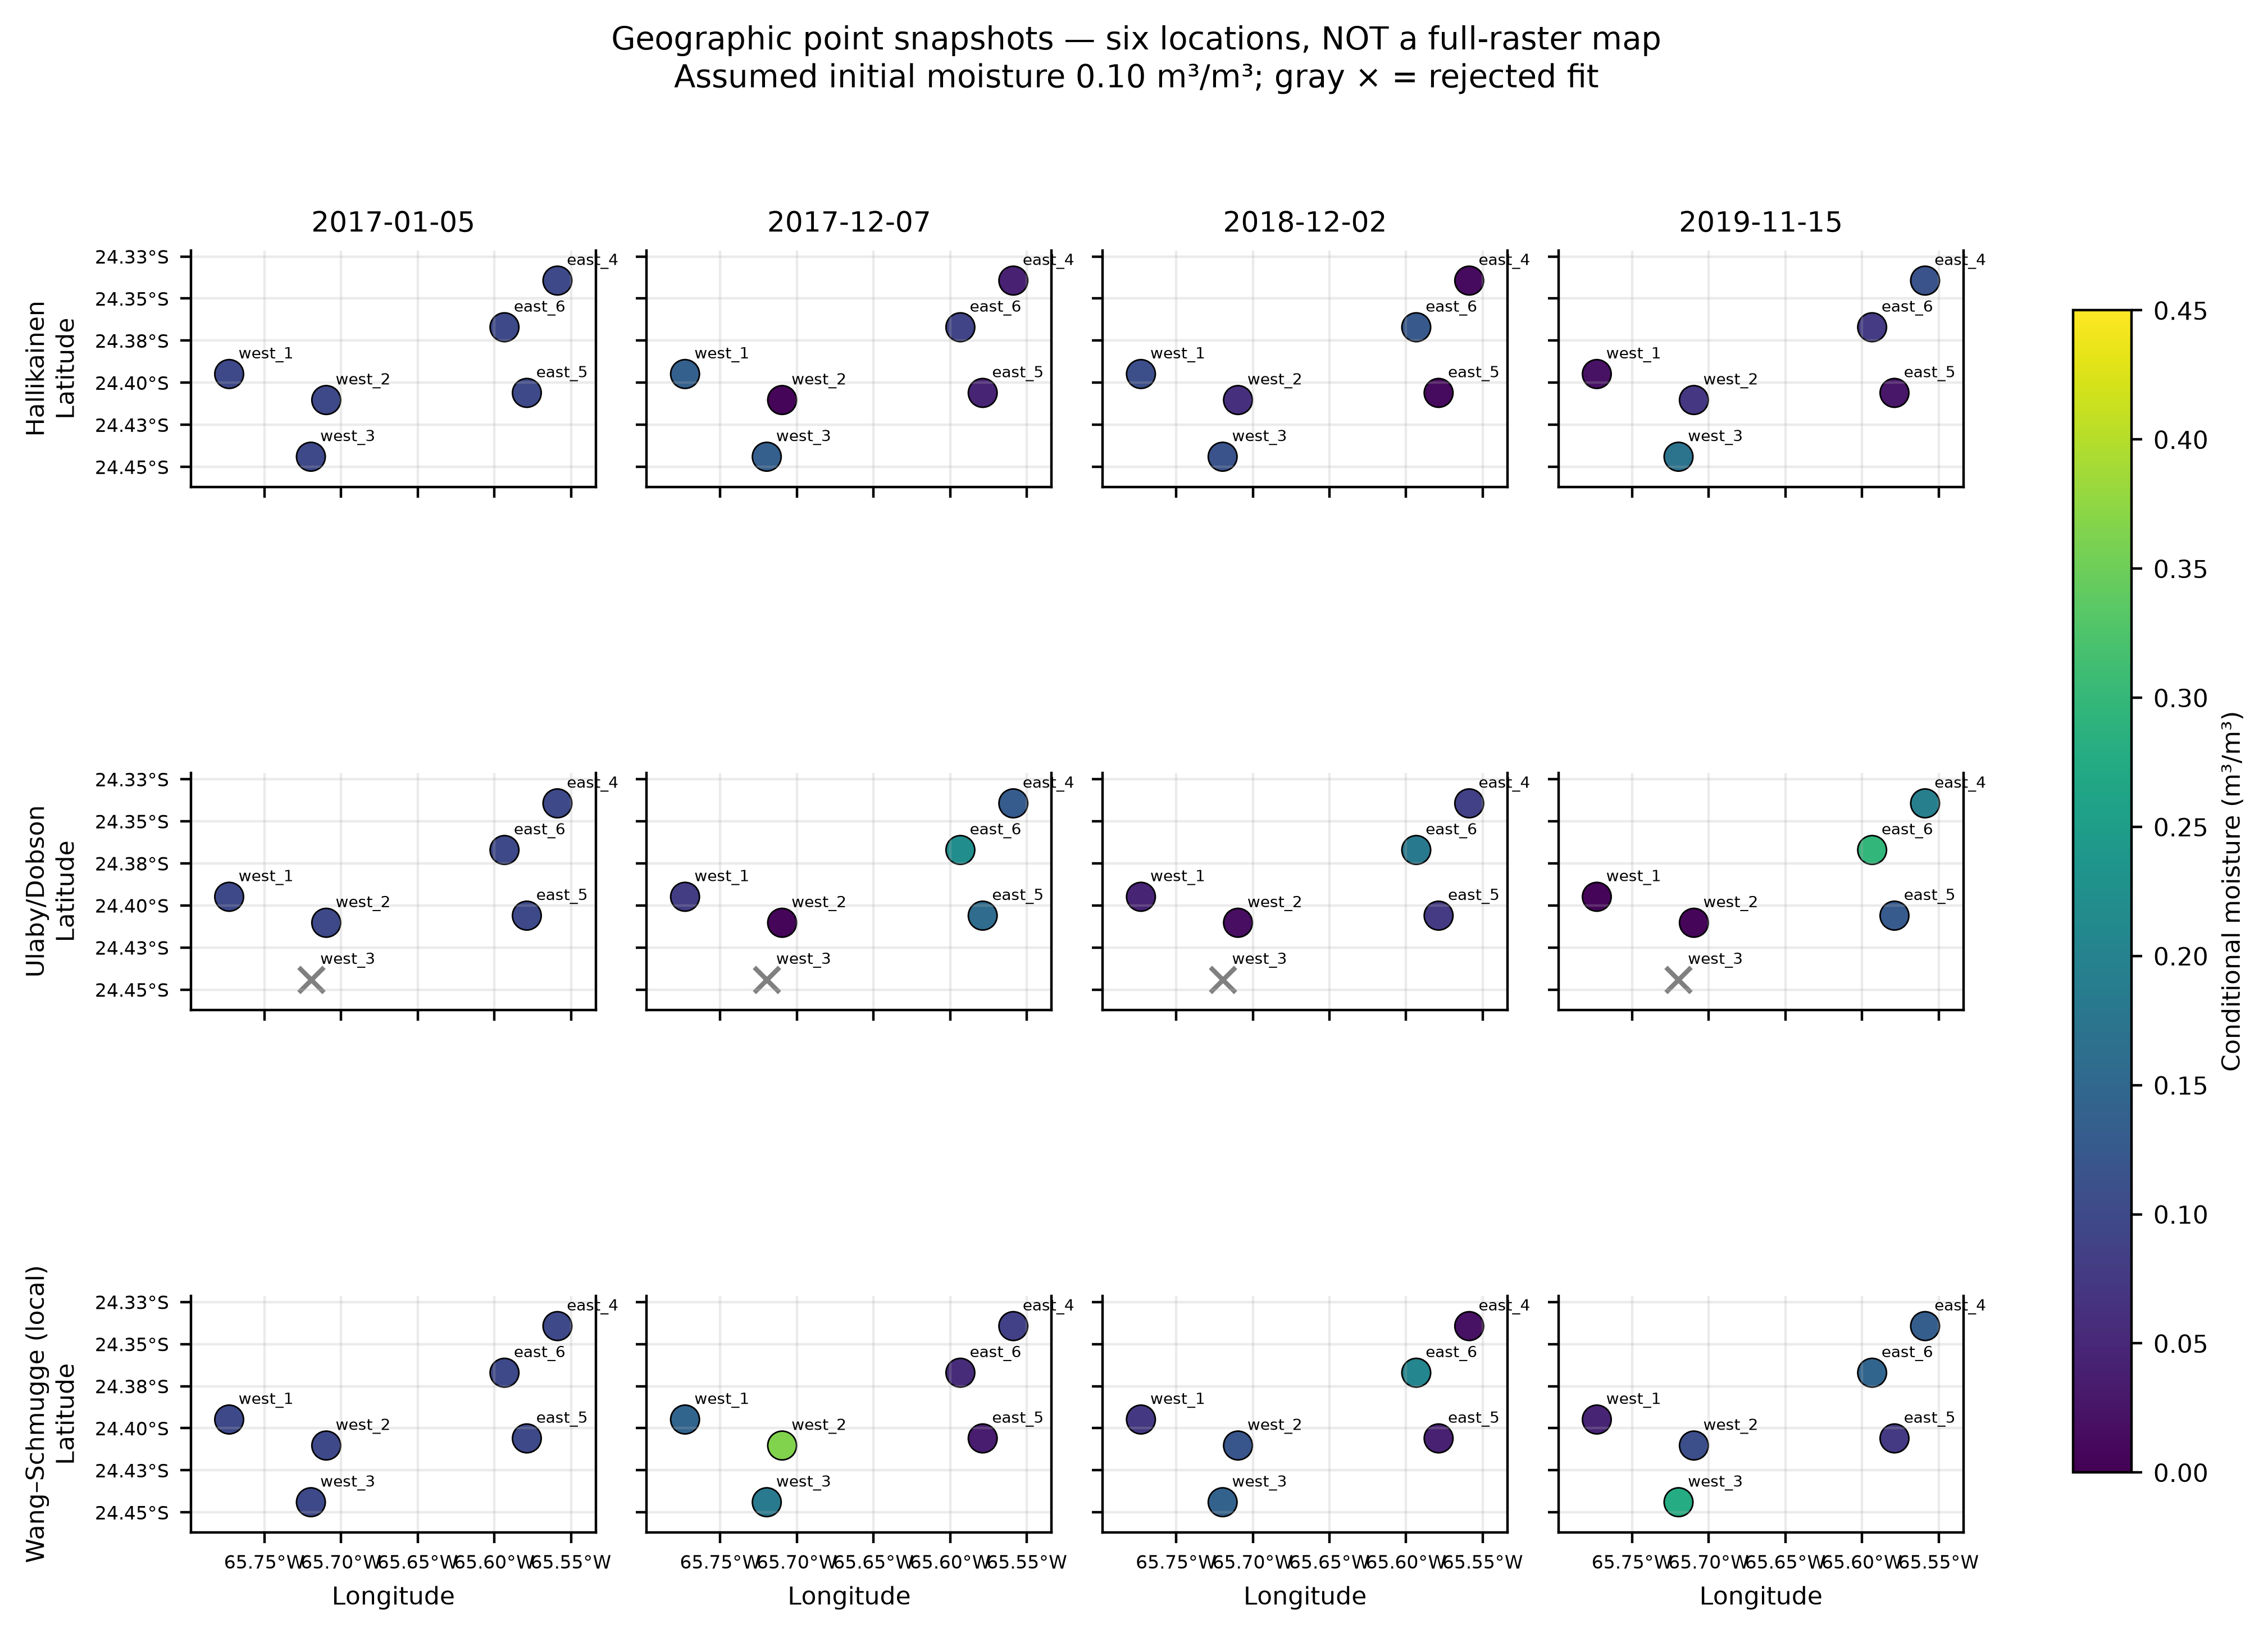

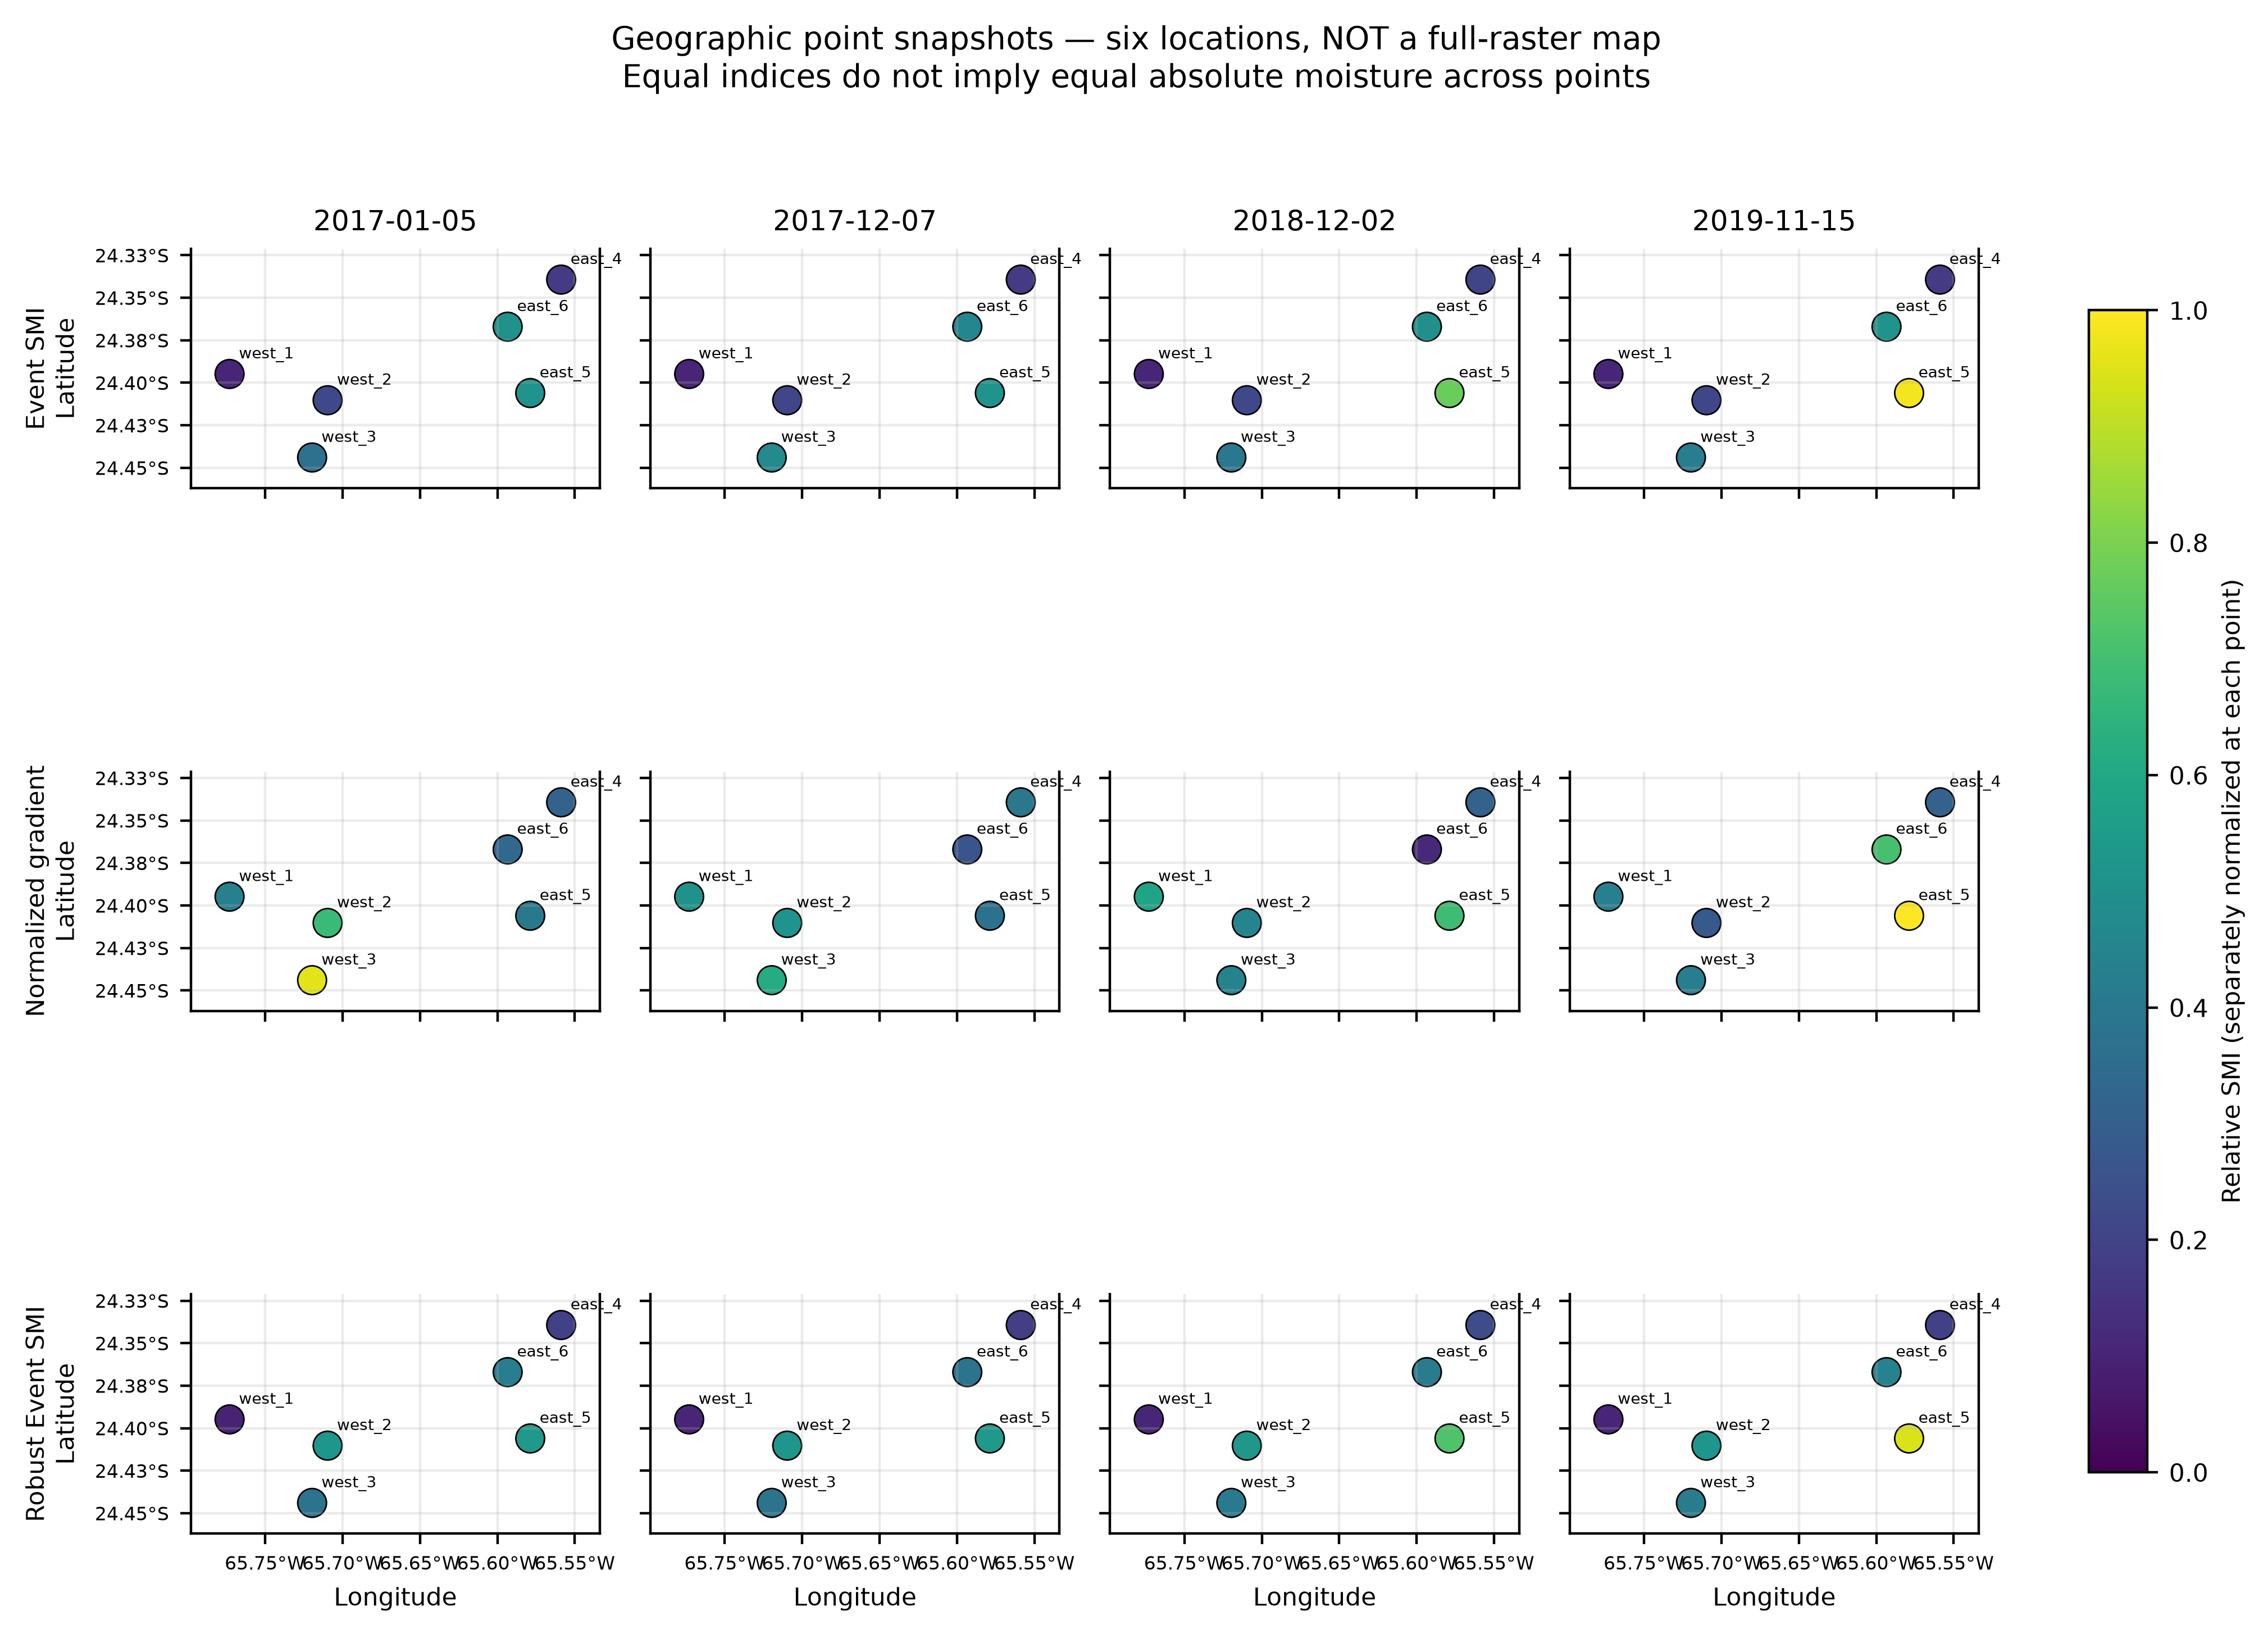

In [4]:
display(Markdown('## Geographic snapshots — point support only'))
display(Image(filename=str(figures/'direct_geographic_snapshots.png')))
display(Image(filename=str(figures/'indices_geographic_snapshots.png')))


## Recreate figures

Run `python MiaplPy/plot_moisture_methods_rain_maps.py --output /a/new/output/directory` from the project root using your `sp` environment. The script uses saved H5 inputs only, verifies common dates, and writes PNG/PDF plus a manifest. It never interpolates six points into a raster.

Use `indices_only.png` for the SMI comparison without rainfall. All dates are observed acquisitions; the map selection uses four evenly spaced acquisition indices, not a search for favorable patterns. No absolute-moisture interpretation applies to the 0–1 SMI colorbar.
